In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

df_rotterdam = pd.read_excel('rotterdam_dataset_02.xlsx')
df_rotterdam.head()

,Arrival_Date,Vessel_ID,Vessel_Type,Cargo_tons,Berth_Time_hr
0,2022-01-01 10:33:00,V000001,Container,10597,25.5
1,2022-01-01 19:24:00,V000002,Container,12878,19.2
2,2022-01-01 17:29:00,V000003,Container,11917,24.2
3,2022-01-01 06:23:00,V000004,Container,8757,16.7
4,2022-01-01 05:14:00,V000005,Container,27508,21.8


In [2]:
df_weight = df_rotterdam[['Vessel_Type', 'Cargo_tons']].copy()
df_weight_grouped = df_weight.groupby('Vessel_Type')
df_vessel_means = df_weight_grouped['Cargo_tons'].describe()
df_vessel_means

,count,mean,std,min,25%,50%,75%,max
Vessel_Type,,,,,,,,
Bulk,5133.0,39785.565556,16193.349694,4911.0,27896.0,37853.0,48969.0,144480.0
Container,10420.0,15765.674952,5635.666662,4125.0,11720.0,14809.5,18851.5,56006.0
Tanker,2317.0,51268.459215,15322.487237,19740.0,40182.0,49016.0,60381.0,128221.0


In [3]:
bulk_mean = df_vessel_means['mean'].iloc[0]
bulk_std = df_vessel_means['std'].iloc[0]

container_mean = df_vessel_means['mean'].iloc[1]
container_std = df_vessel_means['std'].iloc[1]

tanker_mean = df_vessel_means['mean'].iloc[2]
tanker_std = df_vessel_means['std'].iloc[2]

In [4]:
def lognormal_moments(mean, variance):
    lognormal_variance = np.log(1 + variance / mean**2)
    lognormal_mean = np.log(mean) - lognormal_variance / 2
    return lognormal_mean, np.sqrt(lognormal_variance)

mu_bulk, sigma_bulk = lognormal_moments(bulk_mean, bulk_std**2)
mu_container, sigma_container = lognormal_moments(container_mean, container_std**2)
mu_tanker, sigma_tanker = lognormal_moments(tanker_mean, tanker_std**2)

In [5]:
logNormDistEst_bulk = stats.lognorm(s=sigma_bulk, scale=np.exp(mu_bulk))
logNormDistEst_container = stats.lognorm(s=sigma_container, scale=np.exp(mu_container))
logNormDistEst_tanker = stats.lognorm(s=sigma_tanker, scale=np.exp(mu_tanker))

In [6]:
df_times = df_rotterdam[['Arrival_Date', 'Vessel_Type']].copy()
df_times = df_times.sort_values(by='Arrival_Date').reset_index(drop=True)
df_times.head()

,Arrival_Date,Vessel_Type
0,2022-01-01 00:04:00,Bulk
1,2022-01-01 00:55:00,Tanker
2,2022-01-01 01:13:00,Tanker
3,2022-01-01 02:08:00,Tanker
4,2022-01-01 02:59:00,Container


In [7]:
df_times_bulk = df_times[df_times['Vessel_Type'] == 'Bulk'].copy()
df_times_bulk['Time_diff'] = df_times_bulk['Arrival_Date'].diff()

df_times_tanker = df_times[df_times['Vessel_Type'] == 'Tanker'].copy()
df_times_tanker['Time_diff'] = df_times_tanker['Arrival_Date'].diff()

df_times_container = df_times[df_times['Vessel_Type'] == 'Container'].copy()
df_times_container['Time_diff'] = df_times_container['Arrival_Date'].diff()

In [8]:
iat_bulk = df_times_bulk['Time_diff'].dropna().dt.total_seconds() / 86400
lam_bulk = 1 / np.mean(iat_bulk)

iat_tanker = df_times_tanker['Time_diff'].dropna().dt.total_seconds() / 86400
lam_tanker = 1 / np.mean(iat_tanker)

iat_container = df_times_container['Time_diff'].dropna().dt.total_seconds() / 86400
lam_container = 1 / np.mean(iat_container)

print(lam_bulk)
print(lam_tanker)
print(lam_container)

4.683989422791703
2.113845873011044
9.508133971291867


In [9]:
def simPoissonProcess(lam, t, cargoDist):
    Nt = 0 # counter
    interArrivalTimeDist = stats.expon(scale = 1 / lam)
    time = interArrivalTimeDist.rvs()
    total_weight = 0
    while time < t:
        Nt += 1
        time += interArrivalTimeDist.rvs()
        total_weight += cargoDist.rvs()
    return Nt, total_weight

In [10]:
def simScenario(lamB, lamC, lamT, distB, distC, distT, nrRuns, t):
    N_B = np.zeros(nrRuns) 
    S_B = np.zeros(nrRuns)
    N_C = np.zeros(nrRuns)
    S_C = np.zeros(nrRuns)
    N_T = np.zeros(nrRuns)
    S_T = np.zeros(nrRuns)
    for i in range(nrRuns):
        N_B[i], S_B[i] = simPoissonProcess(lamB, t, distB)
        N_C[i], S_C[i] = simPoissonProcess(lamC, t, distC)
        N_T[i], S_T[i] = simPoissonProcess(lamT, t, distT)
    return N_B, N_C, N_T, S_B, S_C, S_T

In [11]:
def logNormDist(mean, std):
    mu, sigma = lognormal_moments(mean, std**2)
    return stats.lognorm(s=sigma, scale=np.exp(mu))

In [12]:
def simExceed(lamB, lamC, lamT, distB, distC, distT, nrRuns, capacity):
    exceed = np.zeros(nrRuns)
    for i in range(nrRuns):
        exceed[i] = simPoissonProcess(lamB, 1, distB)[1] + simPoissonProcess(lamC, 1, distC)[1] + simPoissonProcess(lamT, 1, distT)[1] > capacity
    return exceed

In [13]:
years = 5
nrRuns = 200            # simulated years per step (for N and S)
nrRunsExceed = 5000     # simulated days per step (for the exceedance probability)
t = 365
capacity = 650000


# Simulation for 'Growth in trade volume'

meanN_g = np.zeros(years); meanS_g = np.zeros(years); q95N_g = np.zeros(years); q95S_g = np.zeros(years)
stdN_g = np.zeros(years); stdS_g = np.zeros(years)
pExceed_g = np.zeros(years); ciExceed_g = np.zeros((years, 2))

for k in range(1, years + 1):
    g_k = 1.03**k # Assume a 3% per year increase
    N_B, N_C, N_T, S_B, S_C, S_T = simScenario(lam_bulk * g_k, lam_container * g_k, lam_tanker * g_k, logNormDistEst_bulk, logNormDistEst_container, logNormDistEst_tanker, nrRuns, t)
    meanN_g[k-1] = (N_B + N_C + N_T).mean()
    meanS_g[k-1] = (S_B + S_C + S_T).mean()
    stdN_g[k-1] = (N_B + N_C + N_T).std()
    stdS_g[k-1] = (S_B + S_C + S_T).std()
    q95N_g[k-1] = np.quantile(N_B + N_C + N_T, 0.95)
    q95S_g[k-1] = np.quantile(S_B + S_C + S_T, 0.95)

    exceed = simExceed(lam_bulk * g_k, lam_container * g_k, lam_tanker * g_k, logNormDistEst_bulk, logNormDistEst_container, logNormDistEst_tanker, nrRunsExceed, capacity)
    pExceed_g[k-1] = np.mean(exceed)
    halfWidth = 1.96 * np.std(exceed) / np.sqrt(nrRunsExceed)
    ciExceed_g[k-1] = (pExceed_g[k-1] - halfWidth, pExceed_g[k-1] + halfWidth)

    print(k, round(g_k, 3), meanN_g[k-1], meanS_g[k-1], q95N_g[k-1], q95S_g[k-1], stdN_g[k-1], stdS_g[k-1], pExceed_g[k-1], ciExceed_g[k-1])

1 1.03 6134.5 167279786.84590784 6263.2 171388798.59535518 74.54602605102434 2580429.767345509 0.0828 [0.07516132 0.09043868]


2 1.061 6316.355 172087131.53333756 6452.4 176578102.5151042 79.39123991348164 2568566.1037029475 0.0962 [0.08802675 0.10437325]


3 1.093 6506.755 177403672.04978386 6644.15 181657324.18687057 81.96191173343873 2672877.470393305 0.1264 [0.11718912 0.13561088]


4 1.126 6704.325 182640753.90414673 6815.9 187142940.42920762 76.49934231743434 2494099.4876602185 0.1398 [0.13018777 0.14941223]


5 1.159 6889.055 187782779.9927299 7046.0 193108423.90874445 88.19660977044411 2936733.664064047 0.16 [0.1498382 0.1701618]


In [14]:
# Simulation for 'Larger vessels'

years = 5
nrRuns = 200            # simulated years per step (for N and S)
nrRunsExceed = 5000     # simulated days per step (for the exceedance probability)
t = 365
capacity = 650000


meanN_l = np.zeros(years); meanS_l = np.zeros(years); q95N_l = np.zeros(years); q95S_l = np.zeros(years)
stdN_l = np.zeros(years); stdS_l = np.zeros(years)
pExceed_l = np.zeros(years); ciExceed_l = np.zeros((years, 2))

for k in range(1, years + 1):
    c_k = 1.03**k # Assume a 3% increase per year again
    distB = logNormDist(bulk_mean * c_k, bulk_std * c_k)
    distC = logNormDist(container_mean * c_k, container_std * c_k)
    distT = logNormDist(tanker_mean * c_k, tanker_std * c_k)

    N_B, N_C, N_T, S_B, S_C, S_T = simScenario(lam_bulk, lam_container, lam_tanker, distB, distC, distT, nrRuns, t)
    meanN_l[k-1] = (N_B + N_C + N_T).mean()
    meanS_l[k-1] = (S_B + S_C + S_T).mean()
    stdN_l[k-1] = (N_B + N_C + N_T).std()
    stdS_l[k-1] = (S_B + S_C + S_T).std()
    q95N_l[k-1] = np.quantile(N_B + N_C + N_T, 0.95)
    q95S_l[k-1] = np.quantile(S_B + S_C + S_T, 0.95)

    exceed = simExceed(lam_bulk, lam_container, lam_tanker, distB, distC, distT, nrRunsExceed, capacity)
    pExceed_l[k-1] = np.mean(exceed)
    halfWidth = 1.96 * np.std(exceed) / np.sqrt(nrRunsExceed)
    ciExceed_l[k-1] = (pExceed_l[k-1] - halfWidth, pExceed_l[k-1] + halfWidth)

    print(k, round(c_k, 3), meanN_l[k-1], meanS_l[k-1], q95N_l[k-1], q95S_l[k-1], stdN_l[k-1], stdS_l[k-1], pExceed_l[k-1], ciExceed_l[k-1])

1 1.03 5948.085 167070368.00915584 6072.1 171659761.6865077 78.26753972752688 2772951.070455139 0.0844 [0.0766946 0.0921054]


2 1.061 5950.535 172196394.15081942 6073.25 176481227.79100466 77.16941605973184 2662248.1277481895 0.1092 [0.10055485 0.11784515]


3 1.093 5953.855 177261854.42184997 6092.1 181989919.04565644 74.5746872269673 2755036.983413151 0.136 [0.12649839 0.14550161]


4 1.126 5949.015 182451657.47197425 6071.2 186799595.16918877 72.92705105103319 2639694.2478341344 0.1584 [0.14827951 0.16852049]


5 1.159 5945.13 187995492.0435395 6058.05 192441483.8851997 76.39282099778748 2798393.788999082 0.1884 [0.17756117 0.19923883]


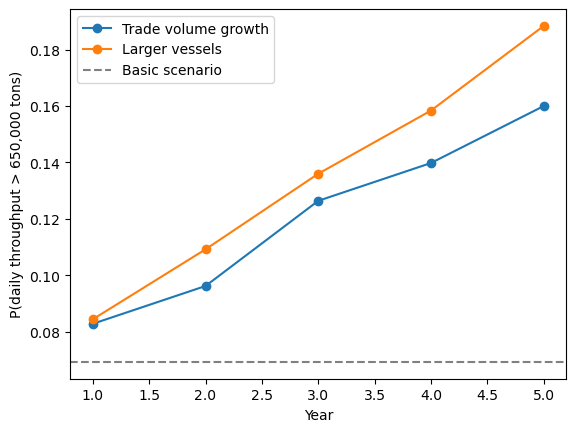

In [15]:
plt.figure()
plt.plot(range(1, years + 1), pExceed_g, marker='o', label='Trade volume growth')
plt.plot(range(1, years + 1), pExceed_l, marker='o', label='Larger vessels')
plt.axhline(0.06928, color='gray', linestyle='--', label='Basic scenario')
plt.xlabel('Year')
plt.ylabel('P(daily throughput > 650,000 tons)')
plt.legend()
plt.show()

In [16]:
def simStrike(days, strikeStart, strikeLength, efficiency, capacity):
    backlog = 0
    peakBacklog = 0
    daysToClear = np.nan
    for day in range(days):
        arrived = simPoissonProcess(lam_bulk, 1, logNormDistEst_bulk)[1] + simPoissonProcess(lam_container, 1, logNormDistEst_container)[1] + simPoissonProcess(lam_tanker, 1, logNormDistEst_tanker)[1]
        if day >= strikeStart and day < strikeStart + strikeLength:
            cap = capacity * efficiency
        else:
            cap = capacity
        backlog = max(0, backlog + arrived - cap)
        peakBacklog = max(peakBacklog, backlog)
        if day >= strikeStart + strikeLength and backlog == 0 and np.isnan(daysToClear):
            daysToClear = day - (strikeStart + strikeLength) + 1
    return peakBacklog, daysToClear

nrRuns = 2000
peak = np.zeros(nrRuns)
clear = np.zeros(nrRuns)
for i in range(nrRuns):
    peak[i], clear[i] = simStrike(60, 0, 7, 0.5, 650000)   # 60-day window, 7-day strike at 50% capacity

print(np.mean(peak), np.quantile(peak, 0.95))
print(np.nanmean(clear), np.nanquantile(clear, 0.95)) # Number of days the port needs to catch up with missed arrivals due to strike

870925.9009511891 1432829.5010559876
4.7775 9.0


In [17]:
# Sensitivity analysis
# 1. other cargo distributions with the same simulated arrivals
# 2. a different arrival rate for every month
np.random.seed(1)

types = ['Bulk', 'Container', 'Tanker']
lam = {'Bulk': lam_bulk, 'Container': lam_container, 'Tanker': lam_tanker}
logNormDistEst = {'Bulk': logNormDistEst_bulk, 'Container': logNormDistEst_container, 'Tanker': logNormDistEst_tanker}
mean = {'Bulk': bulk_mean, 'Container': container_mean, 'Tanker': tanker_mean}
std = {'Bulk': bulk_std, 'Container': container_std, 'Tanker': tanker_std}

cargoData = {}
normDistEst = {}
gammaDistEst = {}
for vesselType in types:
    cargoData[vesselType] = df_weight[df_weight['Vessel_Type'] == vesselType]['Cargo_tons']
    normDistEst[vesselType] = stats.norm(mean[vesselType], std[vesselType])
    alpha = mean[vesselType]**2 / std[vesselType]**2
    beta = mean[vesselType] / std[vesselType]**2
    gammaDistEst[vesselType] = stats.gamma(alpha, scale=1/beta)
    tstGamma = stats.kstest(cargoData[vesselType], gammaDistEst[vesselType].cdf)
    print(f'{vesselType} p-value gamma: {round(tstGamma.pvalue, 4)}')

# arrival rate per month: number of arrivals in that month / number of days in that month
df_days = df_rotterdam.copy()
df_days['Day'] = df_days['Arrival_Date'].dt.date
df_days['Month'] = df_days['Arrival_Date'].dt.month
dailyCargo = df_days.groupby('Day')['Cargo_tons'].sum()

lamMonth = {}
for vesselType in types:
    vessels = df_days[df_days['Vessel_Type'] == vesselType]
    lamMonth[vesselType] = np.zeros(12)
    for month in range(1, 13):
        nrDays = df_days[df_days['Month'] == month]['Day'].nunique()
        lamMonth[vesselType][month-1] = np.sum(vessels['Month'] == month) / nrDays

Bulk p-value gamma: 0.4536
Container p-value gamma: 0.0
Tanker p-value gamma: 0.149


In [18]:
t = 365
capacity = 650000
nrYears = 100
n = nrYears * t
daysInMonth = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

# 1. other cargo distributions with same simulated arrivals
names = ['Lognormal', 'Empirical', 'Normal', 'Gamma']
cargoSim = {}
for name in names:
    cargoSim[name] = np.zeros(n)

for i in range(n):
    for vesselType in types:
        Nt, total_weight = simPoissonProcess(lam[vesselType], 1, logNormDistEst[vesselType])
        cargoSim['Lognormal'][i] += total_weight
        cargoSim['Empirical'][i] += np.sum(np.random.choice(cargoData[vesselType], Nt))
        cargoSim['Normal'][i] += np.sum(normDistEst[vesselType].rvs(Nt))
        cargoSim['Gamma'][i] += np.sum(gammaDistEst[vesselType].rvs(Nt))

# 2. seasonality (different arrival rate for every month)
seasonCargo = np.zeros(n)
monthOfDay = np.zeros(n)
i = 0
for year in range(nrYears):
    for month in range(12):
        for day in range(daysInMonth[month]):
            for vesselType in types:
                Nt, total_weight = simPoissonProcess(lamMonth[vesselType][month], 1, logNormDistEst[vesselType])
                seasonCargo[i] += total_weight
            monthOfDay[i] = month + 1
            i += 1
cargoSim['Seasonal'] = seasonCargo

In [19]:
dataCargo = np.array(dailyCargo)
dataMonth = np.array([d.month for d in dailyCargo.index])
summer = (monthOfDay >= 5) & (monthOfDay <= 8)
dataSummer = (dataMonth >= 5) & (dataMonth <= 8)

dataExceed = dataCargo > capacity
dataSummerShare = np.sum(dataExceed & dataSummer) / np.sum(dataExceed)
print(f'Data mean: {round(np.mean(dataCargo))}, std: {round(np.std(dataCargo))}, 99% quantile: {round(np.quantile(dataCargo, 0.99))}')
print(f'Data P(S > 650000) = {round(np.mean(dataExceed), 4)}, share in May-Aug: {round(dataSummerShare, 2)}')

for name in names + ['Seasonal']:
    x = cargoSim[name]
    exceed = x > capacity
    halfWidth = 1.96 * np.std(exceed) / np.sqrt(n)
    summerShare = np.sum(exceed & summer) / np.sum(exceed)
    print(f'{name} mean: {round(np.mean(x))}, std: {round(np.std(x))}, 99% quantile: {round(np.quantile(x, 0.99))}')
    print(f'{name} P(S > 650000) = {round(np.mean(exceed), 4)}, CI half-width: {round(halfWidth, 4)}, share in May-Aug: {round(summerShare, 2)}')

Data mean: 444605, std: 139408, 99% quantile: 819122
Data P(S > 650000) = 0.0766, share in May-Aug: 0.63
Lognormal mean: 446321, std: 132724, 99% quantile: 789652
Lognormal P(S > 650000) = 0.0724, CI half-width: 0.0027, share in May-Aug: 0.34
Empirical mean: 445614, std: 131588, 99% quantile: 788173
Empirical P(S > 650000) = 0.0692, CI half-width: 0.0026, share in May-Aug: 0.34
Normal mean: 445898, std: 131834, 99% quantile: 785930
Normal P(S > 650000) = 0.0688, CI half-width: 0.0026, share in May-Aug: 0.35
Gamma mean: 446194, std: 132272, 99% quantile: 787397
Gamma P(S > 650000) = 0.07, CI half-width: 0.0026, share in May-Aug: 0.33
Seasonal mean: 444716, std: 138289, 99% quantile: 809308
Seasonal P(S > 650000) = 0.0772, CI half-width: 0.0027, share in May-Aug: 0.61


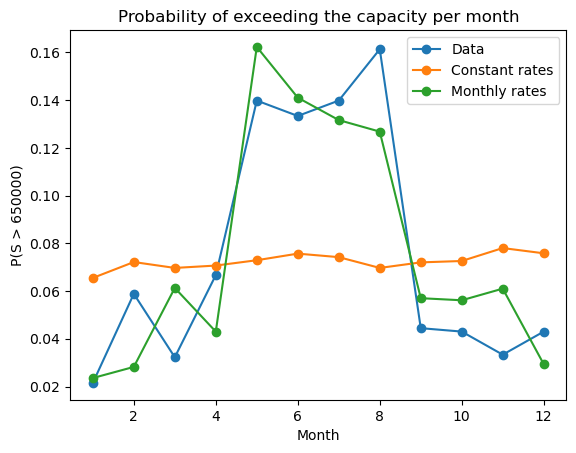

In [20]:
pExceed_data = np.zeros(12)
pExceed_basic = np.zeros(12)
pExceed_season = np.zeros(12)
for month in range(1, 13):
    pExceed_data[month-1] = np.mean(dataCargo[dataMonth == month] > capacity)
    pExceed_basic[month-1] = np.mean(cargoSim['Lognormal'][monthOfDay == month] > capacity)
    pExceed_season[month-1] = np.mean(seasonCargo[monthOfDay == month] > capacity)

plt.figure()
plt.plot(np.arange(1, 13), pExceed_data, 'o-')
plt.plot(np.arange(1, 13), pExceed_basic, 'o-')
plt.plot(np.arange(1, 13), pExceed_season, 'o-')
plt.title('Probability of exceeding the capacity per month')
plt.xlabel('Month')
plt.ylabel('P(S > 650000)')
plt.legend(['Data', 'Constant rates', 'Monthly rates'])
plt.show()